In [1]:
import numpy as np
from tensorflow import keras
from keras.datasets import mnist

## Data Loading and Preprocessing

In [2]:
# load data
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

In [3]:
print(train_images.shape)
print(test_images.shape)

(60000, 28, 28)
(10000, 28, 28)


In [4]:
import matplotlib.pyplot as plt

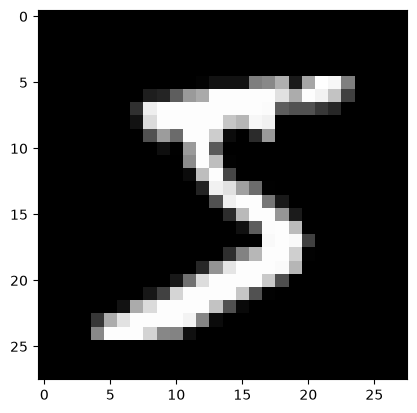

In [5]:
plt.imshow(train_images[0],cmap='gray')
plt.show()

In [6]:
print(train_images[0].shape)

(28, 28)


In [7]:
print(train_images[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

In [8]:
for row in train_images[0]:
    line = ''
    for pixel in row:
        if pixel > 128:
            line = line + '#'
        else:
            line = line + '.'
    print(line)

............................
............................
............................
............................
............................
.................##.###.....
...........############.....
........##########..........
........##########..........
.........#.###...#..........
...........##...............
...........###..............
............##..............
.............###............
..............###...........
...............####.........
.................###........
.................###........
...............#####........
.............#######........
............######..........
..........######............
.......#######..............
.....########...............
....#######.................
............................
............................
............................


In [9]:
# In neuron networks, it's easier to represent pixel in 0 to 1 than 0 to 255
# since each pixel is 0 to 255 (0 to 2^8 -1)
# we can simply divide pixel by 255 to normalize
img_train = train_images / 255
img_test = test_images / 255

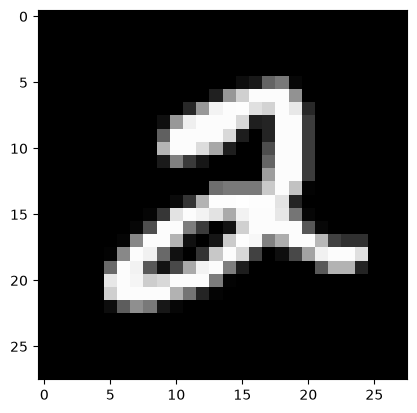

2


In [10]:
# to work more conveniently with label
idx = 5
plt.imshow(train_images[idx],cmap='gray')
plt.show()
print(train_labels[idx])

In [11]:
from keras.utils import to_categorical
lbl_train = to_categorical(train_labels, 10)
lbl_test = to_categorical(test_labels, 10)

## Model 1: Regular Neural Network

In [12]:
num_samples, img_rows, img_cols = img_train.shape
img_train = img_train.reshape(num_samples, img_rows * img_cols)

In [13]:
from keras.models import Sequential
from keras.layers import Input, Dense
nn_model = Sequential([
    Input(shape=(img_rows * img_cols,)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

In [14]:
nn_model.compile(optimizer='adam',
              loss = 'categorical_crossentropy',
              metrics=['accuracy'])

In [15]:
nn_model.fit(img_train, lbl_train, epochs=8, batch_size=32)

Epoch 1/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 455us/step - accuracy: 0.9269 - loss: 0.2558
Epoch 2/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 453us/step - accuracy: 0.9668 - loss: 0.1129
Epoch 3/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 459us/step - accuracy: 0.9766 - loss: 0.0769
Epoch 4/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 452us/step - accuracy: 0.9818 - loss: 0.0587
Epoch 5/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 450us/step - accuracy: 0.9861 - loss: 0.0456
Epoch 6/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 470us/step - accuracy: 0.9895 - loss: 0.0356
Epoch 7/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 451us/step - accuracy: 0.9912 - loss: 0.0289
Epoch 8/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 449us/step - accuracy: 0.9920 - loss: 0.0243


In [16]:
num_samples_test, _, _ = img_test.shape
img_test = img_test.reshape(num_samples_test, img_rows * img_cols)

In [17]:
evaluation = nn_model.evaluate(img_test, lbl_test)
print(evaluation)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 292us/step - accuracy: 0.9782 - loss: 0.0798
[0.07983197271823883, 0.9782000184059143]


In [18]:
predictions = nn_model.predict(img_test[:20,:])
print(predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
[[1.58516048e-10 3.29292288e-11 1.21319941e-08 3.68365691e-05
  3.88314858e-12 2.51138865e-09 2.43474757e-17 9.99962986e-01
  5.20604893e-08 1.43240314e-07]
 [1.54858992e-12 1.83306838e-07 9.99999642e-01 8.66658496e-08
  4.96970306e-20 1.39689602e-08 1.89287119e-09 2.84831501e-19
  1.84471549e-08 3.71638300e-16]
 [5.71444012e-08 9.98399496e-01 1.04076833e-04 4.28875353e-07
  7.37197915e-05 2.70457131e-05 5.08130506e-05 3.96167816e-05
  1.30141713e-03 3.41645864e-06]
 [9.99999523e-01 7.85284598e-12 2.14635861e-07 7.42377687e-11
  7.38162331e-09 1.06614966e-08 1.95547116e-07 1.05168070e-08
  1.62684720e-12 3.53651664e-09]
 [1.27625965e-10 1.21164645e-12 1.46745921e-10 6.56355612e-12
  9.99805689e-01 2.39162690e-10 8.86613061e-10 7.44039284e-08
  1.23788135e-09 1.94114255e-04]
 [2.39558284e-09 9.99785125e-01 1.61612448e-07 4.07955980e-08
  2.70086293e-05 1.41185836e-07 7.51025979e-08 1.63133634e-04
  2.34394920e-05 9.02619888e-07]
 [4.03445750e-13 1.5

In [19]:
predictions_idx = predictions.argmax(1)
print(predictions_idx)
print(test_labels[:20])

[7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]
[7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


In [20]:
nn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305,312 (1.16 MB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,542 (795.09 KB)

## Model 2: Convolutional Neural Network

In [21]:
# Implement a Convolutional Neural Network (CNN)  with 
# 3 convolution layers, 3 pooling layers, and 3 dense layers
from keras.layers import Conv2D, MaxPool2D, Flatten
cnn_model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3,3), activation = 'relu'),
    MaxPool2D((2,2)),
    Conv2D(32, (3,3), activation = 'relu'),
    MaxPool2D((2,2)),
    Conv2D(32, (3,3), activation = 'relu'),
    MaxPool2D((2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation = 'softmax')
])

In [22]:
cnn_model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [23]:
img_train_cnn = img_train.reshape(-1, 28, 28, 1)
img_test_cnn = img_test.reshape(-1, 28, 28, 1)

cnn_model.fit(img_train_cnn, lbl_train, epochs=8, batch_size=32)

Epoch 1/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9173 - loss: 0.2592
Epoch 2/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9722 - loss: 0.0917
Epoch 3/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9785 - loss: 0.0705
Epoch 4/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9829 - loss: 0.0564
Epoch 5/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9853 - loss: 0.0472
Epoch 6/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9878 - loss: 0.0404
Epoch 7/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9888 - loss: 0.0350
Epoch 8/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9903 - loss: 0.0319


In [24]:
evaluation = cnn_model.evaluate(img_test_cnn, lbl_test)
print(evaluation)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 880us/step - accuracy: 0.9850 - loss: 0.0525
[0.052476972341537476, 0.9850000143051147]


In [25]:
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,840 (374.38 KB)

 Trainable params: 31,946 (124.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 63,894 (249.59 KB)